# Baseline 2 — Task-Loss Balance Training (Exp15 / Exp16)

Executed Exp15 snapshot recovered from local handoff. This notebook preserves the recorded experiment and reviews existing evidence. Read the local record guide before running any code.


## Local record guide — Exp15

**Objective:** Executed Exp15 snapshot recovered from local handoff.

**Architecture:** Baseline 2 uses one shared ResNet-50 backbone and separate 55-class crop and 175-class disease heads. The original method, dataset, training and analysis sections follow. The saved-evidence section at the end adds tables, existing figures and a concise discussion for this stage.

**Reading this completed record:** original execution counts, outputs and error records are preserved from `.handoff_work/Baseline2_Stage1_Handoff/02_Single_Stage_Optimisation/Exp15_disease_weight15_EXECUTED.ipynb`. They describe the historical execution, before these presentation/path changes. New Markdown is derived from explicitly linked artifacts; it is not a newly executed experiment.

The local setup cell locates the project root before Python imports. All original code cells are guarded by `RUN_RECORDED_WORKFLOW=False` so Run All in review mode does not train, infer, or rewrite reports. Keep that setting for review; read the saved results directly. Reproducing a historical workflow requires deliberate configuration of its controls and a fresh output directory. Original overwrite protections remain.

**Navigation:** introduction → setup → dataset → model/method → training/results → visualisation → discussion. Some optional historical cells were never executed; do not treat them as results.


## 1. Choose ONE disease-loss weight and run GPU preflight

For the first run leave `EXPERIMENT_TO_RUN="exp15_disease_weight15"`. After results are reviewed, you may choose `exp16_disease_weight20` and restart the kernel. Do not overwrite existing experiment folders.


In [ ]:
# Local review setup: no training, inference, or result writes.
from pathlib import Path
import os
import sys
_override = os.environ.get("B2_PROJECT_ROOT")
_start = Path(_override).expanduser().resolve() if _override else Path.cwd().resolve()
_candidates = [_start] if _override else [_start, *_start.parents]
PROJECT_DIR = next((p for p in _candidates if (p / "model.py").is_file()
                    and (p / "evaluate.py").is_file() and (p / "splits_v2").is_dir()), None)
if PROJECT_DIR is None:
    raise FileNotFoundError("Open the Baseline2 workspace or set B2_PROJECT_ROOT to its root.")
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))
RUN_RECORDED_WORKFLOW = False  # Keep False to review this completed record.
print("Project:", PROJECT_DIR, "| Historical workflow disabled; saved outputs retained.")


In [1]:
if RUN_RECORDED_WORKFLOW:
    from pathlib import Path
    from dataclasses import dataclass
    import copy
    import gc
    import json
    import math
    import platform
    import random
    import tempfile
    import time

    import numpy as np
    import pandas as pd
    from PIL import Image
    import matplotlib.pyplot as plt
    import torch
    from torch import nn
    from torch.utils.data import DataLoader
    import torchvision
    from torchvision import transforms as T
    from torchvision.transforms import InterpolationMode

    from model_resnet50 import MultiTaskResNet50, load_resnet50_checkpoint as load_checkpoint
    from evaluate import (DPDDataset, MEAN, STD, evaluate_loader, generalisation_metrics,
                          validate_development_splits, validation_transform,
                          make_candidates, require_candidate_coverage,
                          sha256_file, synthetic_self_test)

    PROJECT_DIR = PROJECT_DIR
    SPLIT_DIR = PROJECT_DIR / "splits_v2"
    DATASET_ROOT = PROJECT_DIR.parent / "DPD_Small_dataset"
    IMAGE_ROOT = DATASET_ROOT
    OUTPUT_ROOT = PROJECT_DIR / "outputs"

    # ONE experiment per Run All; change only this selector for a later, optional run.
    EXPERIMENT_TO_RUN = "exp15_disease_weight15"  # or "exp16_disease_weight20"

    BASE_CONFIG = {
        "backbone": "resnet50", "pretrained_weights": "IMAGENET1K_V2",
        "crop_classes": 55, "disease_classes": 175, "image_size": 224,
        "batch_size": 16, "max_epochs": 30, "patience": 15, "min_delta": 1e-6,
        "backbone_lr": 1e-5, "head_lr": 1e-3, "crop_dropout": 0.3, "disease_dropout": 0.2,
        "weight_decay": 1e-3, "optimizer": "AdamW", "scheduler": "CosineAnnealingLR",
        "crop_loss_weight": 1.0, "disease_loss_weight": 1.0,
        "seed": 42, "num_workers": 4, "amp": True,
        "crop_scale": [0.85, 1.0], "flip_probability": 0.5, "vertical_flip_probability": 0.5,
        "rotation_degrees": 10, "brightness": 0.15, "contrast": 0.15,
        "interpolation": "bilinear_resize_nearest_rotation", "mean": list(MEAN), "std": list(STD),
        "candidate_mode": "all_pairs", "candidate_catalog": None,
    }
    EXPERIMENTS = {
        "exp15_disease_weight15": {
            "changed_parameter": "Vs Exp09: ONLY disease task CE loss weight changed from 1.0 to 1.5",
            "sampling_method": "natural_shuffle", "sampling_alpha": 0.0,
            "disease_loss_method": "cross_entropy", "disease_cb_beta": None,
            "crop_loss_weight": 1.0, "disease_loss_weight": 1.5,
        },
        "exp16_disease_weight20": {
            "changed_parameter": "Vs Exp09: ONLY disease task CE loss weight changed from 1.0 to 2.0",
            "sampling_method": "natural_shuffle", "sampling_alpha": 0.0,
            "disease_loss_method": "cross_entropy", "disease_cb_beta": None,
            "crop_loss_weight": 1.0, "disease_loss_weight": 2.0,
        },
    }
    if EXPERIMENT_TO_RUN not in EXPERIMENTS:
        raise ValueError(f"Choose one of {list(EXPERIMENTS)}")
    CONFIG = {**BASE_CONFIG, **EXPERIMENTS[EXPERIMENT_TO_RUN], "experiment_id": EXPERIMENT_TO_RUN}
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    EXP09_DIR = OUTPUT_ROOT / "b2_resnet50_exp09_b1matched_seed42"
    EXP10_DIR = OUTPUT_ROOT / "exp10"
    EXPERIMENT_DIR = OUTPUT_ROOT / EXPERIMENT_TO_RUN
    RUN_AUTO_AUDIT = False
    print("PyTorch:", torch.__version__, "torchvision:", torchvision.__version__)
    print("Selected:", EXPERIMENT_TO_RUN)
    print(json.dumps(CONFIG, indent=2))
    if DEVICE.type != "cuda":
        raise RuntimeError("CUDA GPU unavailable. STOP; do not train for hours on CPU.")
    print("GPU:", torch.cuda.get_device_name(0))
    if not IMAGE_ROOT.is_dir() or not SPLIT_DIR.is_dir():
        raise FileNotFoundError("Dataset or splits_v2 folder is missing; ensure notebook is in Baseline2 project root")
    if EXPERIMENT_DIR.exists():
        raise FileExistsError(f"Output already exists: {EXPERIMENT_DIR}. Review old run; never silently overwrite it.")
    gpu_free_bytes, gpu_total_bytes = torch.cuda.mem_get_info()
    print(f"CUDA free VRAM: {gpu_free_bytes / 2**30:.2f}/{gpu_total_bytes / 2**30:.2f} GiB")
    if gpu_free_bytes < 3*2**30:
        raise RuntimeError("Less than 3 GiB free VRAM. Close stale processes and restart kernel first.")
    assert CONFIG["sampling_method"] == "natural_shuffle" and CONFIG["disease_loss_method"] == "cross_entropy"
    assert CONFIG["crop_loss_weight"] == 1.0 and CONFIG["disease_loss_weight"] in (1.5, 2.0)
    print("PREFLIGHT PASSED: exactly ONE chosen training experiment will run.")


PyTorch: 2.11.0+cu128 torchvision: 0.26.0+cu128
Selected: exp15_disease_weight15
{
  "backbone": "resnet50",
  "pretrained_weights": "IMAGENET1K_V2",
  "crop_classes": 55,
  "disease_classes": 175,
  "image_size": 224,
  "batch_size": 16,
  "max_epochs": 30,
  "patience": 15,
  "min_delta": 1e-06,
  "backbone_lr": 1e-05,
  "head_lr": 0.001,
  "crop_dropout": 0.3,
  "disease_dropout": 0.2,
  "weight_decay": 0.001,
  "optimizer": "AdamW",
  "scheduler": "CosineAnnealingLR",
  "crop_loss_weight": 1.0,
  "disease_loss_weight": 1.5,
  "seed": 42,
  "num_workers": 4,
  "amp": true,
  "crop_scale": [
    0.85,
    1.0
  ],
  "flip_probability": 0.5,
  "vertical_flip_probability": 0.5,
  "rotation_degrees": 10,
  "brightness": 0.15,
  "contrast": 0.15,
  "interpolation": "bilinear_resize_nearest_rotation",
  "mean": [
    0.485,
    0.456,
    0.406
  ],
  "std": [
    0.229,
    0.224,
    0.225
  ],
  "candidate_mode": "all_pairs",
  "candidate_catalog": null,
  "changed_parameter": "Vs Exp0

## 2. Verify development splits and class mappings

Same train/validation split and label mapping as Exp09; train 6,905, seen-val 695, unseen-val 400. Validation never used for weight adjustment or training. No official test.


In [2]:
if RUN_RECORDED_WORKFLOW:
    frames, split_report = validate_development_splits(SPLIT_DIR)
    print(json.dumps(split_report, indent=2))
    canonical_metadata = pd.concat(frames.values(), ignore_index=True)
    class_mappings = {
        task: {str(int(row[0])): str(row[1]) for row in
               canonical_metadata[[f"{task}_id", f"{task}_name"]].drop_duplicates().itertuples(index=False, name=None)}
        for task in ("crop", "disease", "composition")
    }
    composition_mapping = canonical_metadata[
        ["composition_id", "crop_id", "disease_id", "composition_name"]
    ].drop_duplicates().sort_values("composition_id").to_dict(orient="records")
    print("Original IDs retained; no new class numbering.")


{
  "counts": {
    "train_fit": 6905,
    "val_seen": 695,
    "val_unseen": 400
  },
  "coverage": {
    "train_fit": {
      "crop_id": 55,
      "disease_id": 175,
      "composition_id": 313
    },
    "val_seen": {
      "crop_id": 55,
      "disease_id": 155,
      "composition_id": 273
    },
    "val_unseen": {
      "crop_id": 10,
      "disease_id": 8,
      "composition_id": 10
    }
  },
  "sha256": {
    "train_fit.csv": "fe02d6099c002b10e5a428c2260d5de50f3e677d3b7454216b2a340e55c2a377",
    "val_seen.csv": "ab8d18a13b28fd5a7b9ea531b8ffbdcf4174fd6920337ee9f1a726129390daf5",
    "val_unseen.csv": "b9eae2a57d8331d97636f4e8a8e32bc2e81704d7180fdac22ae923273aadec67",
    "heldout_compositions.csv": "437f57924eef3e5788ed0993caddd969e08f9f86add64791d944425f4bddfe7f",
    "split_manifest.json": "c120d065677e37db6d00880104684c0cd70ccd1c0774ec4aac2eb4b4b0889df8"
  },
  "image_paths_checked": false
}
Original IDs retained; no new class numbering.


## 3. Augmentation, evaluation transforms and 9,625 candidate pairs

Identical to Exp09/Exp10: training RandomResizedCrop + flips + small rotation/color jitter; evaluation Resize(256) + CenterCrop(224); ImageNet normalization. Changing these would confound the intervention.

In [3]:
if RUN_RECORDED_WORKFLOW:
    def training_transform(config):
        return T.Compose([
            T.RandomResizedCrop(config["image_size"], scale=tuple(config["crop_scale"]),
                                interpolation=InterpolationMode.BILINEAR),
            T.RandomHorizontalFlip(p=config["flip_probability"]),
            T.RandomVerticalFlip(p=config["vertical_flip_probability"]),
            T.RandomRotation(config["rotation_degrees"], interpolation=InterpolationMode.NEAREST),
            T.ColorJitter(brightness=config["brightness"], contrast=config["contrast"]),
            T.ToTensor(), T.Normalize(MEAN, STD),
        ])

    def evaluation_transform(image_size):
        resized = round(image_size * 256 / 224)
        return T.Compose([
            T.Resize(resized, interpolation=InterpolationMode.BILINEAR),
            T.CenterCrop(image_size),
            T.ToTensor(), T.Normalize(MEAN, STD),
        ])


    candidates = make_candidates(CONFIG["candidate_mode"], CONFIG["candidate_catalog"])
    require_candidate_coverage(candidates, list(frames.values()))
    print(f"Candidate mode: {CONFIG['candidate_mode']}; {len(candidates):,} global candidate pairs")
    if CONFIG["candidate_mode"] == "all_pairs":
        print("PROVISIONAL: confirm the same candidate policy with Baseline 1 before comparing results.")


Candidate mode: all_pairs; 9,625 global candidate pairs
PROVISIONAL: confirm the same candidate policy with Baseline 1 before comparing results.


## 4. Reproducibility, natural shuffle and checkpoint I/O

Exactly the Exp09 natural shuffle/seed 42 and worker configuration. No replacement sampling, no class-balanced per-class weighting; only the *task weight* differs. The pretrained ResNet-50 checkpoint is initialized from ImageNet-1K V2 on each run, NOT Exp09's trained weights.


In [4]:
if RUN_RECORDED_WORKFLOW:
    def seed_everything(seed):
        random.seed(seed)
        np.random.seed(seed)
        torch.manual_seed(seed)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.benchmark = False
        torch.backends.cudnn.deterministic = True


    def make_loader(dataset, config, shuffle=False, sampler=None):
        workers = int(config["num_workers"])
        if workers < 0:
            raise ValueError("num_workers must be >= 0")
        generator = torch.Generator().manual_seed(config["seed"])
        if shuffle and sampler is not None:
            raise ValueError("Cannot enable both shuffle and sampler")
        kwargs = dict(batch_size=config["batch_size"], shuffle=shuffle, sampler=sampler,
                      num_workers=workers, pin_memory=DEVICE.type == "cuda",
                      generator=generator, drop_last=False)
        if workers > 0:
            kwargs["prefetch_factor"] = 2
            kwargs["persistent_workers"] = True
        return DataLoader(dataset, **kwargs)


    @dataclass
    class EarlyStopping:
        patience: int = 5
        min_delta: float = 1e-6
        best: float = -math.inf
        bad_epochs: int = 0

        def update(self, value):
            if not math.isfinite(value):
                raise ValueError("Nonfinite validation harmonic mean")
            improved = value > self.best + self.min_delta
            if improved:
                self.best = value
                self.bad_epochs = 0
            else:
                self.bad_epochs += 1
            return improved, self.bad_epochs >= self.patience


    def atomic_checkpoint(payload, path):
        path = Path(path)
        temporary = path.with_suffix(".tmp")
        torch.save(payload, temporary)
        temporary.replace(path)


    def environment_details():
        return {"python": platform.python_version(), "torch": str(torch.__version__),
                "torchvision": str(torchvision.__version__), "numpy": np.__version__,
                "pandas": pd.__version__, "device": str(DEVICE),
                "gpu": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else None,
                "cuda_runtime": torch.version.cuda}


    def make_tempered_disease_sampler(training_frame, alpha=0.25, seed=42):
        """Compute per-image weights exclusively from the existing train-fit labels."""
        if not (0 <= alpha <= 1):
            raise ValueError("alpha must be in [0,1]")
        frequency = training_frame["disease_id"].value_counts()
        if (frequency <= 0).any() or len(training_frame) != 6905:
            raise ValueError("Unexpected train-fit disease frequency / split size")
        per_image_counts = training_frame["disease_id"].map(frequency)
        weights = torch.as_tensor(per_image_counts.to_numpy(dtype=float) ** (-alpha), dtype=torch.double)
        assert len(weights) == len(training_frame) and torch.isfinite(weights).all()
        sampler = torch.utils.data.WeightedRandomSampler(
            weights=weights, num_samples=len(training_frame), replacement=True,
            generator=torch.Generator().manual_seed(seed))
        # Approximate expected draws per label (not a guarantee about realised sampled counts).
        expected = (pd.DataFrame({"disease_id":frequency.index.astype(int),
                     "train_images":frequency.values.astype(int)}).sort_values("disease_id"))
        numerators = expected["train_images"].to_numpy(dtype=float) ** (1-alpha)
        expected["expected_draws_per_epoch"] = len(training_frame) * numerators / numerators.sum()
        return sampler, expected


## 5. CPU synthetic smoke test

Brief CPU-only shape, gradient and checkpoint tests. Real full training remains CUDA + AMP. No Stage 2 and no official test.


In [5]:
if RUN_RECORDED_WORKFLOW:
    def run_smoke_checks():
        synthetic_self_test()
        seed_everything(CONFIG["seed"])
        # Run synthetic smoke check on CPU so it cannot exhaust RTX 4050 VRAM.
        # Section 7 real training still runs on CUDA, with mixed precision.
        smoke_device = torch.device("cpu")
        smoke = MultiTaskResNet50(pretrained=False, crop_dropout=CONFIG["crop_dropout"], disease_dropout=CONFIG["disease_dropout"]).to(smoke_device)
        assert smoke.crop_head[1].in_features == smoke.disease_head[1].in_features == 2048
        assert not ({id(p) for p in smoke.crop_head.parameters()} &
                    {id(p) for p in smoke.disease_head.parameters()})
        groups = smoke.parameter_groups()
        group_ids = [id(p) for group in groups for p in list(group["params"])]
        assert len(group_ids) == len(set(group_ids)) == len(list(smoke.parameters()))
        # Recreate groups because the generator above was consumed.
        optimizer = torch.optim.AdamW(smoke.parameter_groups(), weight_decay=1e-4)
        # Smoke check uses FP32 for stable gradient assertions; real training still uses CUDA AMP.
        scaler = torch.amp.GradScaler("cuda", enabled=False)
        images = torch.randn(2, 3, 64, 64, device=smoke_device)  # Synthetic check, small to reduce CPU load
        with torch.autocast(device_type=smoke_device.type, enabled=False):
            output = smoke(images)
            assert output["crop_logits"].shape == (2, 55)
            assert output["disease_logits"].shape == (2, 175)
            lc = nn.functional.cross_entropy(output["crop_logits"], torch.tensor([0, 54], device=smoke_device))
            ld = nn.functional.cross_entropy(output["disease_logits"], torch.tensor([0, 174], device=smoke_device))
        shared_parameter = next(smoke.backbone.parameters())
        for loss in (lc, ld):
            gradient = torch.autograd.grad(loss, shared_parameter, retain_graph=True)[0]
            assert torch.isfinite(gradient).all() and gradient.abs().sum() > 0
        loss = CONFIG["crop_loss_weight"] * lc + CONFIG["disease_loss_weight"] * ld
        assert torch.isfinite(loss) and CONFIG["disease_loss_weight"] > CONFIG["crop_loss_weight"]
        scaler.scale(loss).backward()
        for module in (smoke.backbone, smoke.crop_head, smoke.disease_head):
            grads = [p.grad for p in module.parameters() if p.grad is not None]
            assert grads and all(torch.isfinite(g).all() for g in grads)
        scaler.step(optimizer)
        scaler.update()
        smoke.eval()
        with torch.no_grad():
            before = smoke(images)["crop_logits"].cpu()
        with tempfile.TemporaryDirectory() as directory:
            path = Path(directory) / "synthetic.pt"
            atomic_checkpoint({"model_state": smoke.state_dict(), "config": CONFIG}, path)
            restored, _ = load_checkpoint(path, smoke_device)
            with torch.no_grad():
                after = restored(images)["crop_logits"].cpu()
            assert torch.allclose(before, after, atol=1e-6, rtol=1e-5)
        stopper = EarlyStopping()
        assert stopper.update(0) == (True, False)
        for _ in range(4):
            assert stopper.update(0) == (False, False)
        assert stopper.update(0) == (False, True)
        assert stopper.update(0.1) == (True, False)
        assert stopper.update(0.1 + 1e-8) == (False, False)
        del smoke, restored, images, output, loss, lc, ld, optimizer
        gc.collect()
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()
        print("CPU synthetic checks passed; actual Section 7 training remains CUDA + AMP.")

    run_smoke_checks()


Synthetic metric + Exp06 calibration checks passed; no dataset accessed.
CPU synthetic checks passed; actual Section 7 training remains CUDA + AMP.


## 6. Shared trainer — cross-entropy and disease task weight

Training loss: `L_total = 1.0 × L_crop_CE + λ_d × L_disease_CE` with λ_d = 1.5 or 2.0. Both heads and the shared backbone are trainable. Different loss magnitudes can also alter optimization dynamics; improvements are empirical, not guaranteed.

**Validation and overfitting:** HM selects checkpoints; weighted validation losses are plotted for comparability with weighted train loss. Also inspect crop/disease validation losses separately.


In [6]:
if RUN_RECORDED_WORKFLOW:
    def train_one_epoch(model, loader, optimizer, scaler, device, amp=True,
                        crop_loss_weight=1.0, disease_loss_weight=1.0, disease_class_weights=None):
        model.train()
        totals = np.zeros(3, dtype=float)
        n_images = 0
        crop_criterion = nn.CrossEntropyLoss()
        disease_criterion = nn.CrossEntropyLoss(weight=disease_class_weights)
        for batch in loader:
            images = batch["image"].to(device, non_blocking=True)
            crop = batch["crop"].to(device, non_blocking=True)
            disease = batch["disease"].to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            try:
                with torch.autocast(device_type=device.type, enabled=amp and device.type == "cuda"):
                    result = model(images)
                    crop_loss = crop_criterion(result["crop_logits"], crop)
                    disease_loss = disease_criterion(result["disease_logits"], disease)
                    total_loss = crop_loss_weight * crop_loss + disease_loss_weight * disease_loss
                if not torch.isfinite(total_loss):
                    raise RuntimeError("Nonfinite training loss; stop and inspect the inputs/configuration.")
                scaler.scale(total_loss).backward()
                scaler.step(optimizer)
                scaler.update()
            except torch.cuda.OutOfMemoryError as error:
                raise RuntimeError("CUDA out of memory. Restart the kernel, explicitly reduce batch_size to 8, "
                                   "record the change, and rerun as a new experiment. No setting was changed automatically.") from error
            count = images.shape[0]
            totals += count * np.array([total_loss.item(), crop_loss.item(), disease_loss.item()])
            n_images += count
        if not n_images:
            raise ValueError("Empty training loader")
        return dict(zip(("total_loss", "crop_loss", "disease_loss"), (totals / n_images).tolist()))


    def plot_training_history(history, best_epoch, path):
        table = pd.DataFrame(history)
        fig, axes = plt.subplots(2, 2, figsize=(12, 8))
        axes[0, 0].plot(table.epoch, table.train_total_loss, label="Training")
        # Evaluate-loader total_loss is unweighted; reweight validation task losses
        # to make this graph comparable with the weighted train_total_loss.
        cw = float(CONFIG["crop_loss_weight"])
        dw = float(CONFIG["disease_loss_weight"])
        for split,label in (("seen", "Seen validation"), ("unseen", "Unseen validation")):
            weighted = cw * table[f"{split}_crop_loss"] + dw * table[f"{split}_disease_loss"]
            axes[0, 0].plot(table.epoch, weighted, label=label)
        axes[0, 0].set(title=f"Task-weighted CE: crop {cw:g} + disease {dw:g}", ylabel="Mean weighted loss")
        axes[0, 1].plot(table.epoch, table.train_crop_loss, label="Crop")
        axes[0, 1].plot(table.epoch, table.train_disease_loss, label="Disease")
        axes[0, 1].set(title="Training task losses", ylabel="Mean loss")
        axes[1, 0].plot(table.epoch, table.seen_composition_top1 * 100, label="Seen-like")
        axes[1, 0].plot(table.epoch, table.unseen_composition_top1 * 100, label="Unseen-like")
        axes[1, 0].set(title="Composition Top-1 validation", ylabel="Accuracy (%)")
        axes[1, 1].plot(table.epoch, table.composition_harmonic_mean * 100, label="Harmonic mean")
        axes[1, 1].set(title="Development selection criterion", ylabel="Accuracy (%)")
        for ax in axes.flat:
            ax.axvline(best_epoch, linestyle="--", color="black", alpha=.5, label=f"Best epoch {best_epoch}")
            ax.set_xlabel("Epoch")
            ax.grid(alpha=.2)
            ax.legend(fontsize=8)
        fig.tight_layout()
        fig.savefig(path, dpi=160)
        return fig


    def fit_stage1(config, train_loader, seen_loader, unseen_loader, candidate_pairs,
                   metadata_report, mappings, composition_map, output_root=OUTPUT_ROOT):
        seed_everything(config["seed"])
        run_config = copy.deepcopy(config)
        run_config["candidate_catalog"] = (str(config["candidate_catalog"])
                                             if config["candidate_catalog"] is not None else None)
        # A failed pretrained download is an error, never a random-weight fallback.
        model = MultiTaskResNet50(crop_dropout=config["crop_dropout"],
                                disease_dropout=config["disease_dropout"], pretrained=True).to(DEVICE)
        optimizer = torch.optim.AdamW(model.parameter_groups(config["backbone_lr"], config["head_lr"]),
                                     weight_decay=config["weight_decay"])
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=config["max_epochs"])
        amp_enabled = config["amp"] and DEVICE.type == "cuda"
        scaler = torch.amp.GradScaler("cuda", enabled=amp_enabled)
        stopper = EarlyStopping(config["patience"], config["min_delta"])
        output_dir = Path(output_root) / config["experiment_id"]
        output_dir.mkdir(parents=True, exist_ok=False)
        environment = environment_details()
        (output_dir / "config.json").write_text(json.dumps({"config": run_config, "environment": environment,
             "development_split": metadata_report, "class_mappings": mappings,
             "composition_mapping": composition_map,
             "candidate_pairs": candidate_pairs.cpu().tolist(),
             "candidate_policy_status": "provisional" if config["candidate_mode"] == "all_pairs" else "user-supplied group catalogue",
             "accuracy_units": "fractions in [0,1]"}, indent=2), encoding="utf-8")
        disease_class_weights = None
        if config["disease_loss_method"] == "effective_number":
            freq = np.bincount(frames["train_fit"]["disease_id"].to_numpy(dtype=int),
                                minlength=config["disease_classes"])
            if len(freq) != 175 or np.any(freq <= 0):
                raise ValueError("All 175 disease classes must be present in train_fit for this experiment")
            beta = float(config["disease_cb_beta"])
            if not (0.0 < beta < 1.0):
                raise ValueError("CB beta must be in (0, 1)")
            # Expm1 improves numerical stability when beta is near 1.
            effective_n = -np.expm1(freq * np.log(beta)) / (1.0-beta)
            weights = 1.0 / effective_n
            weights = weights / weights.mean()  # scale doesn't change PyTorch's weighted-mean CE
            disease_class_weights = torch.tensor(weights, device=DEVICE, dtype=torch.float32)
            pd.DataFrame({"disease_id": np.arange(175), "train_images": freq,
                          "effective_number": effective_n, "normalized_loss_weight": weights}).to_csv(
                              output_dir / "disease_effective_number_weights.csv", index=False)
            print("Class-balanced disease loss: beta=", beta,
                  "weights min/max=", f"{weights.min():.3f}/{weights.max():.3f}")
        elif config["disease_loss_method"] != "cross_entropy":
            raise ValueError("Unsupported disease loss method")
        history = []
        best_epoch = None
        start = time.perf_counter()
        for epoch in range(1, config["max_epochs"] + 1):
            epoch_start = time.perf_counter()
            rates = [group["lr"] for group in optimizer.param_groups]
            training = train_one_epoch(model, train_loader, optimizer, scaler, DEVICE, amp_enabled,
                                       config["crop_loss_weight"], config["disease_loss_weight"], disease_class_weights)
            seen, _ = evaluate_loader(model, seen_loader, DEVICE, candidate_pairs, amp_enabled)
            unseen, _ = evaluate_loader(model, unseen_loader, DEVICE, candidate_pairs, amp_enabled)
            joint = generalisation_metrics(seen, unseen)
            row = {"epoch": epoch, "backbone_lr": rates[0], "head_lr": rates[1],
                   **{f"train_{key}": value for key, value in training.items()},
                   **{f"seen_{key}": value for key, value in seen.items()},
                   **{f"unseen_{key}": value for key, value in unseen.items()},
                   "composition_harmonic_mean": joint["composition_harmonic_mean"],
                   "seen_unseen_gap": joint["seen_unseen_gap"],
                   "epoch_seconds": time.perf_counter() - epoch_start}
            history.append(row)
            pd.DataFrame(history).to_csv(output_dir / "training_history.csv", index=False)
            improved, stop = stopper.update(joint["composition_harmonic_mean"])
            scheduler.step()
            if improved:
                best_epoch = epoch
                best_metrics = {"epoch": epoch, "seen": seen, "unseen": unseen, **joint}
                atomic_checkpoint({"stage": 1, "epoch": epoch, "model_state": model.state_dict(),
                    "optimizer_state": optimizer.state_dict(), "scheduler_state": scheduler.state_dict(),
                    "scaler_state": scaler.state_dict(), "config": run_config,
                    "candidate_pairs": candidate_pairs.cpu().tolist(),
                    "class_mappings": mappings, "composition_mapping": composition_map,
                    "development_split": metadata_report, "environment": environment,
                    "best_metrics": best_metrics, "parameter_count": sum(p.numel() for p in model.parameters())},
                    output_dir / "best_development.pt")
            print(f"Epoch {epoch:02d} | loss {training['total_loss']:.4f} | "
                  f"seen {seen['composition_top1']:.2%} | unseen {unseen['composition_top1']:.2%} | "
                  f"HM {joint['composition_harmonic_mean']:.2%}" + (" * best" if improved else ""))
            if stop:
                print(f"Early stopping after {config['patience']} consecutive non-improving epochs.")
                break
        best = torch.load(output_dir / "best_development.pt", map_location=DEVICE, weights_only=True)
        model.load_state_dict(best["model_state"])
        model.eval()
        validation_metrics = {**best["best_metrics"], "epochs_run": len(history),
                              "training_seconds": time.perf_counter() - start,
                              "accuracy_units": "fractions in [0,1]"}
        (output_dir / "validation_metrics.json").write_text(json.dumps(validation_metrics, indent=2), encoding="utf-8")
        log = {"experiment_id": config["experiment_id"], "changed_parameter": config["changed_parameter"],
               "best_epoch": best_epoch, **generalisation_metrics(best["best_metrics"]["seen"], best["best_metrics"]["unseen"]),
               "candidate_mode": config["candidate_mode"], "checkpoint_path": str(output_dir / "best_development.pt"),
               "configuration": json.dumps(run_config, sort_keys=True)}
        pd.DataFrame([log]).to_csv(output_dir / "experiment_summary.csv", index=False)
        figure = plot_training_history(history, best_epoch, output_dir / "training_curves.png")
        plt.show()
        return model, history, validation_metrics, output_dir


## 7. Run ONE selected Stage 1 experiment (GPU + AMP)

Exp15 default. Do not change config after training starts, and do not click Run All twice. Best HM checkpoint saved as `outputs/<experiment_id>/best_development.pt`. Separate configuration and metrics are preserved.


Natural shuffle; disease task weight = 1.5 ; no WeightedRandomSampler / effective-number class weighting
Epoch 01 | loss 4.9161 | seen 50.94% | unseen 0.00% | HM 0.00% * best
Epoch 02 | loss 2.3276 | seen 59.14% | unseen 0.00% | HM 0.00%
Epoch 03 | loss 1.6666 | seen 61.87% | unseen 0.75% | HM 1.48% * best
Epoch 04 | loss 1.2824 | seen 66.76% | unseen 1.25% | HM 2.45% * best
Epoch 05 | loss 1.0370 | seen 68.20% | unseen 0.75% | HM 1.48%
Epoch 06 | loss 0.8853 | seen 69.06% | unseen 1.75% | HM 3.41% * best
Epoch 07 | loss 0.7432 | seen 70.36% | unseen 1.75% | HM 3.42% * best
Epoch 08 | loss 0.6465 | seen 71.37% | unseen 2.00% | HM 3.89% * best
Epoch 09 | loss 0.5742 | seen 70.79% | unseen 2.00% | HM 3.89%
Epoch 10 | loss 0.5348 | seen 71.94% | unseen 1.50% | HM 2.94%
Epoch 11 | loss 0.4608 | seen 72.23% | unseen 1.50% | HM 2.94%
Epoch 12 | loss 0.4191 | seen 72.52% | unseen 4.25% | HM 8.03% * best
Epoch 13 | loss 0.3788 | seen 72.37% | unseen 1.50% | HM 2.94%
Epoch 14 | loss 0.3616 | se

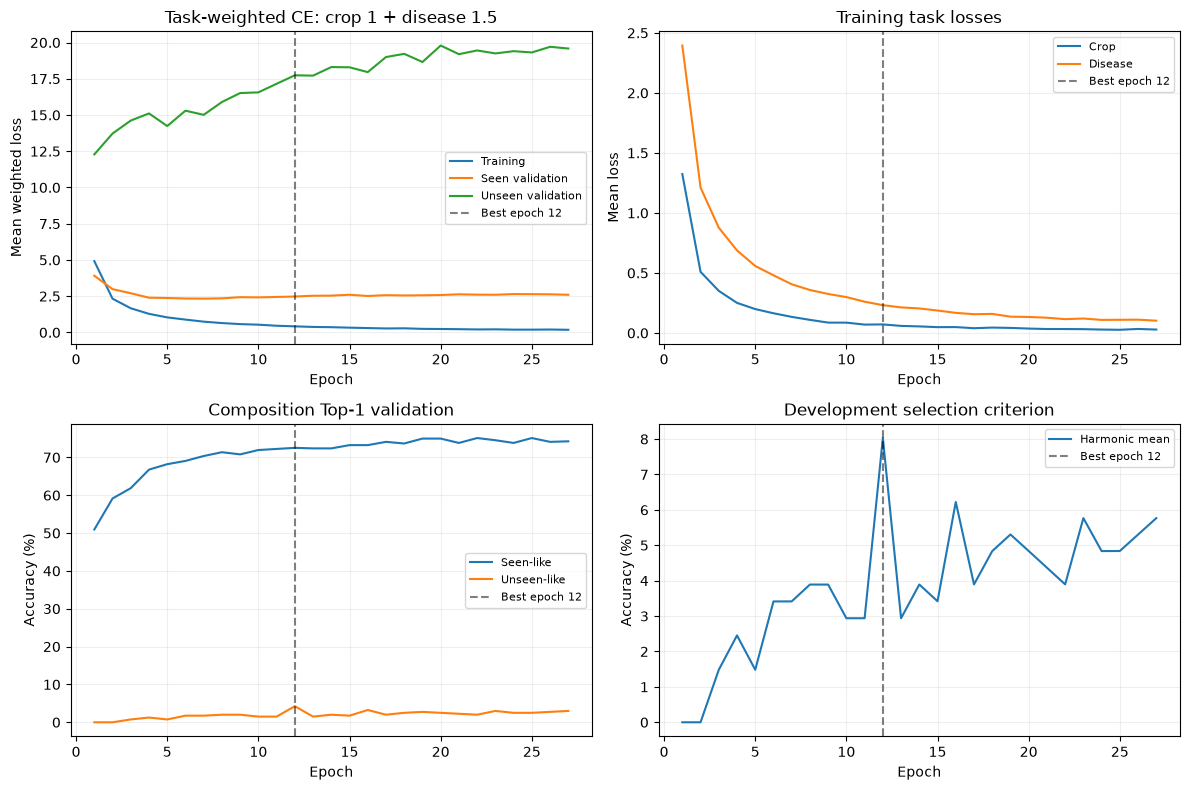

FINISHED exp15_disease_weight15 best epoch 12 saved to c:\AML\ML_Project\Baseline2\outputs\exp15_disease_weight15
Training closed; starting development-only audit. No second training job will start.


In [7]:
if RUN_RECORDED_WORKFLOW:
    # Confirm the same split hashes and all-pair candidate policy were loaded.
    frames, verified_report = validate_development_splits(SPLIT_DIR)
    candidates = make_candidates(CONFIG["candidate_mode"], CONFIG["candidate_catalog"])
    require_candidate_coverage(candidates, list(frames.values()))
    for nm, frame in frames.items():
        if len(frame) != {"train_fit":6905,"val_seen":695,"val_unseen":400}[nm]:
            raise ValueError(f"Unexpected {nm} image count: {len(frame)}")

    datasets = {name: DPDDataset(frame, IMAGE_ROOT,
        training_transform(CONFIG) if name=="train_fit" else evaluation_transform(CONFIG["image_size"]))
        for name,frame in frames.items()}
    # Decode all metadata-listed development images before spending GPU time.
    for dataset in datasets.values():
        for path in dataset.paths:
            with Image.open(path) as im: im.convert("RGB").load()
    verified_report["image_paths_checked"] = True
    verified_report["image_decoding_checked"] = True
    sampler = None
    exposure_table = None
    assert CONFIG["sampling_method"] == "natural_shuffle"
    print("Natural shuffle; disease task weight =", CONFIG["disease_loss_weight"],
          "; no WeightedRandomSampler / effective-number class weighting")
    loaders = {name: make_loader(ds, CONFIG,
        shuffle=(name=="train_fit" and sampler is None),
        sampler=(sampler if name=="train_fit" else None)) for name,ds in datasets.items()}
    seed_everything(CONFIG["seed"])
    example = next(iter(loaders["val_seen"]))
    assert tuple(example["image"].shape[1:]) == (3,224,224)
    model, history, metrics, experiment_dir = fit_stage1(
        CONFIG,loaders["train_fit"],loaders["val_seen"],loaders["val_unseen"],
        candidates,verified_report,class_mappings,composition_mapping)
    if exposure_table is not None:
        exposure_table.to_csv(experiment_dir/"expected_disease_sampling_exposure.csv",index=False)
    print("FINISHED", EXPERIMENT_TO_RUN,"best epoch",metrics["epoch"],"saved to",experiment_dir)
    del loaders,datasets,example,sampler,model
    gc.collect()
    plt.close("all")
    if DEVICE.type == "cuda": torch.cuda.empty_cache()
    print("Training closed; starting development-only audit. No second training job will start.")


## 8. Evaluate saved best checkpoint (development-only)

Use the same crop/disease class mappings and all 9,625 candidate pairs as Exp09. Saves validation predictions and error breakdown.


In [8]:
if RUN_RECORDED_WORKFLOW:
    if RUN_AUTO_AUDIT:
        ckpt = EXPERIMENT_DIR / "best_development.pt"
        if not ckpt.is_file():
            raise FileNotFoundError("Selected checkpoint missing; cannot audit")
        diagnostic_model, saved = load_checkpoint(ckpt, DEVICE)
        assert saved["stage"] == 1 and saved["config"]["experiment_id"] == EXPERIMENT_TO_RUN
        assert saved["development_split"]["sha256"] == split_report["sha256"], "Split mismatch"
        saved_candidates = torch.as_tensor(saved["candidate_pairs"], dtype=torch.long)
        train_pair_set = set(map(tuple, frames["train_fit"][["crop_id", "disease_id"]].to_numpy().tolist()))
        predictions, audit_summary = {}, []
        for split in ("val_seen", "val_unseen"):
            ds = DPDDataset(frames[split], IMAGE_ROOT, evaluation_transform(CONFIG["image_size"]))
            dl = make_loader(ds, saved["config"], shuffle=False)
            metrics_split, records = evaluate_loader(diagnostic_model, dl, DEVICE, saved_candidates,
                                                       amp=saved["config"]["amp"], collect_predictions=True)
            tab = pd.DataFrame(records)
            assert len(tab) == len(frames[split]) and tab.filename.is_unique
            tab["crop_correct"] = tab.crop_id == tab.predicted_crop_id
            tab["disease_correct"] = tab.disease_id == tab.predicted_disease_id
            tab["crop_only_wrong"] = ~tab.crop_correct & tab.disease_correct
            tab["disease_only_wrong"] = tab.crop_correct & ~tab.disease_correct
            tab["both_wrong"] = ~tab.crop_correct & ~tab.disease_correct
            tab["predicted_pair_seen_in_training"] = [
                (int(c), int(d)) in train_pair_set
                for c,d in zip(tab.predicted_pair_crop_id, tab.predicted_pair_disease_id)]
            if int((tab.crop_correct & tab.disease_correct).sum()) != round(metrics_split["composition_top1"] * len(tab)):
                print("Warning: independent head argmax and composition ranking differ (possible score ties).")
            predictions[split] = tab
            tab.to_csv(EXPERIMENT_DIR / f"{split}_error_predictions.csv", index=False)
            audit_summary.append({"split":split, "n":len(tab),
                "crop_top1":metrics_split["crop_top1"],
                "disease_top1":metrics_split["disease_top1"],
                "composition_top1":metrics_split["composition_top1"],
                "composition_top5":metrics_split["composition_top5"],
                "disease_only_wrong_count":int(tab.disease_only_wrong.sum()),
                "crop_only_wrong_count":int(tab.crop_only_wrong.sum()),
                "both_wrong_count":int(tab.both_wrong.sum()),
                "predicted_pair_seen_in_training_rate":float(tab.predicted_pair_seen_in_training.mean())})
        audit_table = pd.DataFrame(audit_summary)
        audit_table.to_csv(EXPERIMENT_DIR / "task_error_breakdown.csv",index=False)
        display(audit_table)
        print("Saved Experiment predictions + error breakdown")
    else:
        print("Auto audit disabled. No evaluation performed.")


,split,n,crop_top1,disease_top1,composition_top1,composition_top5,disease_only_wrong_count,crop_only_wrong_count,both_wrong_count,predicted_pair_seen_in_training_rate
0,val_seen,695,0.886331,0.753957,0.72518,0.864748,112,20,59,0.926619
1,val_unseen,400,0.705000,0.220000,0.04250,0.107500,265,71,47,0.850000


Saved Experiment predictions + error breakdown


## 9. Per-class accuracy: minority disease diagnosis

Focus on `spider_mites`, `bacterial_blight`, `angular_leaf_spot` and whether larger disease weight improved disease-only mistakes and final composition HM.


In [9]:
if RUN_RECORDED_WORKFLOW:
    if RUN_AUTO_AUDIT:
        class_counts = {}
        for task in ("crop", "disease", "composition"):
            idcol, namecol = f"{task}_id", f"{task}_name"
            table = (frames["train_fit"].groupby([idcol, namecol], dropna=False)
                     .size().rename("train_images").reset_index()
                     .sort_values(["train_images",namecol], ascending=[True,True]))
            for split in ("val_seen", "val_unseen"):
                counts = frames[split].groupby(idcol).size().rename(f"{split}_images")
                table = table.join(counts,on=idcol)
            table[["val_seen_images","val_unseen_images"]] = table[["val_seen_images","val_unseen_images"]].fillna(0).astype(int)
            table.to_csv(EXPERIMENT_DIR / f"{task}_class_counts.csv",index=False)
            class_counts[task] = table
            print(f"{task}: {len(table)} labels | min {int(table.train_images.min())} | median {table.train_images.median():g} | max {int(table.train_images.max())}")

        MIN_SUPPORT = 5
        per_class = {}
        for split, pred in predictions.items():
            for task in ("crop", "disease"):
                idcol, namecol, predcol = f"{task}_id", f"{task}_name", f"predicted_{task}_id"
                rows = pred.assign(_correct=(pred[idcol]==pred[predcol]).astype(int))
                score = rows.groupby(idcol).agg(n_validation=(idcol,"size"), n_correct=("_correct","sum")).reset_index()
                score["top1_accuracy"] = score.n_correct / score.n_validation
                names = class_counts[task][[idcol,namecol,"train_images"]]
                score=score.merge(names,on=idcol,how="left",validate="one_to_one")
                score["n_wrong"] = score.n_validation - score.n_correct
                errs = rows.loc[rows._correct==0]
                frequent_wrong = (errs.groupby([idcol,predcol]).size().rename("mistake_count")
                   .reset_index().sort_values("mistake_count",ascending=False).drop_duplicates(idcol))
                freq_names = dict(zip(names[idcol],names[namecol]))
                frequent_wrong["most_common_wrong_prediction"] = frequent_wrong[predcol].map(freq_names)
                score=score.merge(frequent_wrong[[idcol,"most_common_wrong_prediction","mistake_count"]],
                                  on=idcol,how="left")
                score=score.sort_values(["top1_accuracy","n_validation"],ascending=[True,False])
                per_class[(split,task)]=score
                score.to_csv(EXPERIMENT_DIR / f"{split}_{task}_per_class.csv",index=False)
                eligible=score.loc[score.n_validation>=MIN_SUPPORT]
                print(f"\n{split} {task}: {len(eligible)} classes with n >= {MIN_SUPPORT}")
                display(eligible[[namecol,"train_images","n_validation","top1_accuracy","most_common_wrong_prediction"]].head(6))
                display(eligible.sort_values(["top1_accuracy","n_validation"],ascending=[False,False])
                        [[namecol,"train_images","n_validation","top1_accuracy","most_common_wrong_prediction"]].head(6))
    else:
        print("Audit disabled")


crop: 55 labels | min 2 | median 38 | max 1007
disease: 175 labels | min 1 | median 8 | max 1417
composition: 313 labels | min 1 | median 6 | max 500

val_seen crop: 27 classes with n >= 5


,crop_name,train_images,n_validation,top1_accuracy,most_common_wrong_prediction
4,bean,27,5,0.400000,blackgram
5,pepper_bell,56,7,0.714286,tomato
38,pear,94,9,0.777778,apple
49,tea,40,9,0.777778,tomato
19,coffee,121,14,0.785714,citrus
27,grape,152,15,0.800000,papaya


,crop_name,train_images,n_validation,top1_accuracy,most_common_wrong_prediction
13,cassava,959,84,1.0,NaN
47,sugarcane,147,15,1.0,NaN
53,wheat,124,13,1.0,NaN
40,potato,133,12,1.0,NaN
32,olive,107,10,1.0,NaN
37,peanut,114,9,1.0,NaN



val_seen disease: 39 classes with n >= 5


,disease_name,train_images,n_validation,top1_accuracy,most_common_wrong_prediction
48,green_mottle,59,5,0.000000,mosaic
53,spot,83,12,0.416667,streak_virus
11,marssonina_blotch,75,7,0.428571,rust
106,hispa,67,6,0.500000,blast
146,septoria_leaf_spot,167,15,0.533333,target_spot
28,downy_mildew,58,11,0.545455,rust


,disease_name,train_images,n_validation,top1_accuracy,most_common_wrong_prediction
83,streak_virus,201,17,1.000000,NaN
126,diabrotica_speciosa,67,6,1.000000,NaN
3,black_rot,31,5,1.000000,NaN
119,slug,60,5,1.000000,NaN
49,mosaic,518,46,0.978261,mosaic_virus
9,healthy,1417,126,0.944444,mosaic


... (2 outputs left out)

,crop_name,train_images,n_validation,top1_accuracy,most_common_wrong_prediction
8,tomato,1007,70,1.000000,NaN
9,wheat,124,5,1.000000,NaN
7,potato,133,70,0.928571,tomato
3,cassava,959,117,0.888889,corn
1,bean,27,18,0.833333,blackgram
6,mango,100,18,0.777778,olive



val_unseen disease: 8 classes with n >= 5


,disease_name,train_images,n_validation,top1_accuracy,most_common_wrong_prediction
4,bacterial_blight,27,117,0.000000,brown_spot
5,spider_mites,5,70,0.000000,target_spot
3,angular_leaf_spot,7,18,0.000000,bean_rust
6,bacterial_leaf_streak,12,5,0.000000,rust
1,monillia_laxa,8,9,0.111111,eriosoma_lanigerum
7,late_blight,103,70,0.242857,early_blight


,disease_name,train_images,n_validation,top1_accuracy,most_common_wrong_prediction
0,healthy,1417,51,0.921569,mosaic
2,powdery_mildew,150,60,0.383333,sooty_mould
7,late_blight,103,70,0.242857,early_blight
1,monillia_laxa,8,9,0.111111,eriosoma_lanigerum
4,bacterial_blight,27,117,0.000000,brown_spot
5,spider_mites,5,70,0.000000,target_spot


## 10. Confusion matrices and weak/strong class visualizations

Same reporting method as previous Stage-1 experiments; figures saved in the new run folder.


In [10]:
if RUN_RECORDED_WORKFLOW:
    if RUN_AUTO_AUDIT:
        for split, pred in predictions.items():
            for task in ("crop","disease"):
                idcol, namecol, predcol = f"{task}_id", f"{task}_name", f"predicted_{task}_id"
                freq = class_counts[task]
                id_to_name=dict(zip(freq[idcol],freq[namecol]))
                all_ids=sorted(freq[idcol].unique().tolist())
                full = pd.crosstab(pred[idcol],pred[predcol]).reindex(index=all_ids,columns=all_ids,fill_value=0)
                full.index=[f"{i}: {id_to_name[i]}" for i in all_ids]
                full.columns=[f"{i}: {id_to_name[i]}" for i in all_ids]
                full.to_csv(EXPERIMENT_DIR / f"{split}_{task}_full_confusion.csv")
                qualified=per_class[(split,task)].query("n_validation >= @MIN_SUPPORT")
                selections={"weakest":qualified.head(6),
                            "strongest":qualified.sort_values(["top1_accuracy","n_validation"],ascending=[False,False]).head(6)}
                for label,selected in selections.items():
                    chosen=selected[idcol].tolist()
                    small=pred.loc[pred[idcol].isin(chosen),[idcol,predcol]].copy()
                    common=(small.loc[small[idcol]!=small[predcol],predcol]
                            .value_counts().head(5).index.tolist())
                    columns=["Correct"]+[f"{int(p)}: {id_to_name.get(int(p),p)}" for p in common]+["Other wrong"]
                    counts, labels=[],[]
                    for target in chosen:
                        part=small.loc[small[idcol]==target]
                        vals=[int((part[predcol]==target).sum())]
                        vals += [int(((part[predcol]==p)&(part[predcol]!=target)).sum()) for p in common]
                        vals.append(int(((part[predcol]!=target)&(~part[predcol].isin(common))).sum()))
                        assert sum(vals)==len(part), "Confusion row counts do not match support"
                        counts.append(vals)
                        labels.append(f"{id_to_name[target]} (n={len(part)})")
                    matrix=pd.DataFrame(counts,index=labels,columns=columns)
                    matrix.to_csv(EXPERIMENT_DIR / f"{split}_{task}_{label}_confusion_summary.csv")
                    fig,ax=plt.subplots(figsize=(max(8,2+len(columns)*1.2),max(4, len(chosen)*0.6+1)))
                    im=ax.imshow(matrix.to_numpy(), aspect="auto")
                    ax.set_xticks(np.arange(len(columns)),labels=columns,rotation=45,ha="right",fontsize=8)
                    ax.set_yticks(np.arange(len(labels)),labels=labels,fontsize=9)
                    for (i,j),value in np.ndenumerate(matrix.to_numpy()):
                        ax.text(j,i,str(value),ha="center",va="center",fontsize=8)
                    ax.set_title(f"{EXPERIMENT_TO_RUN} {split} {task} — {label} classes (counts)")
                    fig.colorbar(im,ax=ax,label="Images")
                    fig.tight_layout()
                    fig.savefig(EXPERIMENT_DIR / f"{split}_{task}_{label}_confusion_summary.png",dpi=135,bbox_inches="tight")
                    plt.close(fig)
        print("Saved all eight weak/strong confusion summary charts, CSVs and four full confusion matrices")
    else:
        print("Audit disabled")


Saved all eight weak/strong confusion summary charts, CSVs and four full confusion matrices


## 11. Development comparison and summary

Include completed Exp09/10/13/14 if available. Tables preserve uncalibrated Stage-1 metrics only. This section uses plain strings to avoid an optional `tabulate` dependency.


In [11]:
if RUN_RECORDED_WORKFLOW:
    records=[]
    for name,path in [
        ("Exp09 natural shuffle (λd=1.0)", EXP09_DIR),
        ("Exp10 tempered alpha=0.25", EXP10_DIR),
        ("Exp13 tempered alpha=0.5", OUTPUT_ROOT / "exp13_tempered_alpha05"),
        ("Exp14 class-balanced disease", OUTPUT_ROOT / "exp14_effective_number_disease"),
        (EXPERIMENT_TO_RUN,EXPERIMENT_DIR),
    ]:
        mfile=path/"validation_metrics.json"
        if not mfile.is_file():
            print("Reference missing (optional):",mfile)
            continue
        obj=json.loads(mfile.read_text(encoding="utf-8"))
        records.append({"experiment":name,"best_epoch":obj["epoch"],
            "seen_comp":obj["seen"]["composition_top1"],
            "unseen_comp":obj["unseen"]["composition_top1"],
            "HM":obj["composition_harmonic_mean"],
            "unseen_crop":obj["unseen"]["crop_top1"],
            "unseen_disease":obj["unseen"]["disease_top1"],
            "unseen_correct_of_400":round(obj["unseen"]["composition_top1"]*400)})
    comparison = pd.DataFrame(records)
    comparison.to_csv(EXPERIMENT_DIR/"exp09_exp10_new_development_comparison.csv",index=False)
    display(comparison)

    base_name="Exp09 natural shuffle (λd=1.0)"
    if base_name in comparison.experiment.tolist():
        row= comparison.loc[comparison.experiment==EXPERIMENT_TO_RUN].iloc[0]
        base=comparison.loc[comparison.experiment==base_name].iloc[0]
        diffs={key:(float(row[key])-float(base[key]))*100 for key in
               ["seen_comp","unseen_comp","HM","unseen_crop","unseen_disease"]}
    else:
        diffs={}
    train_unseen=per_class[("val_unseen","disease")]
    rare=train_unseen.loc[train_unseen.n_validation>=5].sort_values("top1_accuracy").head(8)
    view_cols=["disease_name","train_images","n_validation","top1_accuracy","most_common_wrong_prediction"]
    msg=[f"# {EXPERIMENT_TO_RUN} — Development-only training results", "",
         f"- Intervention: {CONFIG['changed_parameter']}",
         "- All other key Exp09 settings fixed: ResNet50_V2, batch16, size224, seed42, LR 1e-5/1e-3, AdamW, weight decay 1e-3, 9,625 candidate pairs.",
         f"- Best epoch: {metrics['epoch']} (selected on development composition HM)",
         f"- Seen composition: {metrics['seen']['composition_top1']:.2%}",
         f"- Unseen composition: {metrics['unseen']['composition_top1']:.2%}",
         f"- HM: {metrics['composition_harmonic_mean']:.2%}",
         f"- Unseen crop: {metrics['unseen']['crop_top1']:.2%}; unseen disease: {metrics['unseen']['disease_top1']:.2%}",
         f"- Unseen correct: {round(metrics['unseen']['composition_top1']*400)}/400", ""]
    if diffs:
        msg.append("## Difference from Exp09 (percentage points)")
        for k,v in diffs.items(): msg.append(f"- {k}: {v:+.2f} pp")
        msg.append("")
    msg += ["## Weak unseen disease classes (>=5 validation images)",
            "```text\n" + rare[view_cols].to_string(index=False) + "\n```","",
            "## Protocol and limits",
            "- No Stage 2, official test, calibration or re-training of reference checkpoints.",
            "- Single seed (42); development set used many times. These are exploratory comparisons, not independent test scores.",
            "- Do not interpret changes as statistically robust without multi-seed / independent evaluation.",
            "- This controlled experiment changes ONLY disease task-loss weight from Exp09; Exp13/14 are separate controlled comparisons.",
            "- Original official test is not accessed or used for selection."]
    (EXPERIMENT_DIR/"leader_summary.md").write_text("\n".join(msg)+"\n",encoding="utf-8")
    print("Saved comparison and leader_summary.md:",EXPERIMENT_DIR)
    # Release GPU audit model too, after all its outputs were saved.
    if "diagnostic_model" in globals():
        del diagnostic_model
        gc.collect()
        torch.cuda.empty_cache()


,experiment,best_epoch,seen_comp,unseen_comp,HM,unseen_crop,unseen_disease,unseen_correct_of_400
0,Exp09 natural shuffle (λd=1.0),12,0.729496,0.0400,0.075841,0.7050,0.2200,16
1,Exp10 tempered alpha=0.25,13,0.732374,0.0400,0.075857,0.6925,0.2325,16
2,Exp13 tempered alpha=0.5,28,0.732374,0.0375,0.071347,0.6925,0.2325,15
3,Exp14 class-balanced disease,16,0.726619,0.0375,0.071319,0.6825,0.2300,15
4,exp15_disease_weight15,12,0.725180,0.0425,0.080294,0.7050,0.2200,17


Saved comparison and leader_summary.md: c:\AML\ML_Project\Baseline2\outputs\exp15_disease_weight15


## 12. Optional next run and decision rule

1. First complete **Exp15 λd=1.5**. Compare development HM AND unseen disease accuracy to Exp09. If clearly worse, stop this weight sweep rather than automatically launching more training.
2. If promising, change Section 1 selector to `EXPERIMENT_TO_RUN = "exp16_disease_weight20"`, save, restart kernel, then Run All. This trains ONE NEW model only; nothing overwrites Exp15.
3. Keep calibration experiments Exp11/12 separate as post-hoc extensions. Stage 2 and official test stay untouched.
4. Because the same 400 unseen development images have guided many experiments, this is exploratory selection. Only claim final generalization after model and hyperparameters are fixed and the approved official test is evaluated once.

### References
- Kendall, Gal & Cipolla (CVPR 2018) — Task weighting in multi-task learning: https://openaccess.thecvf.com/content_cvpr_2018/html/Kendall_Multi-Task_Learning_Using_CVPR_2018_paper.html
- Chen et al. (ICML 2018) — GradNorm (possible future alternative, **not implemented here**): https://proceedings.mlr.press/v80/chen18a.html


## Saved evidence and interpretation

This section was assembled from existing local artifacts on 23 November 2026. It does not rerun any model. Historical cell outputs below/above remain unchanged.

### Setup and recorded hyperparameters

| Run | Seed | Batch | LR backbone / head | WD | Crop / disease weight | Sampling |
| --- | --- | --- | --- | --- | --- | --- |
| exp15_disease_weight15 | 42 | 16 | 1e-05 / 0.001 | 0.001 | 1.0 / 1.5 | natural_shuffle |

Exact augmentation, scheduler, class mappings and environment versions are retained in the linked configuration files. Current source settings need not reproduce a historical execution’s environment.

### Dataset and method

Development uses train-fit 6,905 / seen validation 695 / unseen validation 400, with original class IDs and all 9,625 candidate pairs. Recorded ResNet-50 development inference uses BILINEAR Resize(256), CenterCrop(224), ImageNet normalisation (Exp12 reuses Exp11 cached logits; the Exp09 audit reuses saved predictions). Training augmentation and sampling vary by experiment; refer to each saved configuration. No official test metric is used here for model selection.

### Development validation results

| Run | Best epoch | Task | Top-k | Seen (%) | Unseen (%) | HM (%) |
| --- | --- | --- | --- | --- | --- | --- |
| exp15_disease_weight15 | 12 | crop | 1 | 88.6331 | 70.5000 | 78.5334 |
| exp15_disease_weight15 | 12 | crop | 5 | 95.8273 | 76.2500 | 84.9250 |
| exp15_disease_weight15 | 12 | disease | 1 | 75.3957 | 22.0000 | 34.0612 |
| exp15_disease_weight15 | 12 | disease | 5 | 89.9281 | 34.2500 | 49.6068 |
| exp15_disease_weight15 | 12 | composition | 1 | 72.5180 | 4.2500 | 8.0294 |
| exp15_disease_weight15 | 12 | composition | 5 | 86.4748 | 10.7500 | 19.1228 |

Values come from each run’s `validation_metrics.json`. Top-1 composition HM is the saved checkpoint selection criterion. Other HMs above are descriptive calculations from the two saved accuracies, not additional experiments. Validation `total_loss` in the JSON is unweighted crop CE + disease CE; weighted training totals require task-wise weighting before comparison.

### Visualisation and artifact sources


**exp15_disease_weight15**

[config.json](../../../outputs/exp15_disease_weight15/config.json), [validation_metrics.json](../../../outputs/exp15_disease_weight15/validation_metrics.json), [training_history.csv](../../../outputs/exp15_disease_weight15/training_history.csv), [task_error_breakdown.csv](../../../outputs/exp15_disease_weight15/task_error_breakdown.csv), [val_unseen_disease_per_class.csv](../../../outputs/exp15_disease_weight15/val_unseen_disease_per_class.csv), [val_unseen_disease_full_confusion.csv](../../../outputs/exp15_disease_weight15/val_unseen_disease_full_confusion.csv)


![exp15_disease_weight15 — training_curves.png](../../../outputs/exp15_disease_weight15/training_curves.png)


![exp15_disease_weight15 — val_unseen_disease_weakest_confusion_summary.png](../../../outputs/exp15_disease_weight15/val_unseen_disease_weakest_confusion_summary.png)

### Discussion and limitations

Exp15 changes disease CE weight from 1.0 to 1.5 with natural shuffle. Its epoch-12 checkpoint gives 17/400 unseen compositions and HM 8.03%, versus Exp09’s 16/400 and HM 7.58%. It is the selected single-stage configuration and the parent of the final Stage 2 run. A one-image difference on repeatedly used development data is limited evidence, not an independent generalisation claim.

The method uses a fixed task weight of 1.5, not learned uncertainty weighting. The historical Kendall reference provides general multi-task context and is not the implemented algorithm.
